# Download the WESAD data by url

In [7]:
import requests
import zipfile
import os
from bs4 import BeautifulSoup

# Your WESAD Sciebo link
base_url = "https://uni-siegen.sciebo.de/s/HGdUkoNlW1Ub0Gx"

# Try common download forms of the share link
download_urls = [
    base_url + "/download",
    base_url + "?download=1",
    base_url
]

output_path = "/content/WESAD.zip"
session = requests.Session()
downloaded = False

for url in download_urls:
    print(f"\nTrying: {url}")

    try:
        with session.get(
            url,
            stream=True,
            allow_redirects=True,
            timeout=120
        ) as response:

            print("HTTP status:", response.status_code)
            print("Content type:", response.headers.get("Content-Type"))
            print("Final URL:", response.url)

            if response.status_code >= 400:
                print("This URL did not work.")
                continue

            chunks = response.iter_content(chunk_size=1024 * 1024)
            first_chunk = next(chunks, b"")

            # ZIP files normally begin with these bytes
            if first_chunk.startswith(b"PK"):
                print("ZIP file detected. Downloading...")

                with open(output_path, "wb") as f:
                    f.write(first_chunk)

                    total_mb = len(first_chunk) / (1024 * 1024)

                    for chunk in chunks:
                        if chunk:
                            f.write(chunk)
                            total_mb += len(chunk) / (1024 * 1024)

                            if int(total_mb) > 0 and int(total_mb) % 100 == 0:
                                print(f"Downloaded approximately {total_mb:.0f} MB")

                if zipfile.is_zipfile(output_path):
                    print("\nSUCCESS! WESAD ZIP downloaded and verified.")
                    print(f"File: {output_path}")
                    print(f"Size: {os.path.getsize(output_path) / (1024**3):.2f} GB")
                    downloaded = True
                    break
                else:
                    print("The downloaded file is not a valid ZIP.")
                    os.remove(output_path)

            else:
                print("This URL returned a webpage rather than a ZIP file.")

                # Show potentially useful download links on the webpage
                sample = first_chunk
                while len(sample) < 1_000_000:
                    chunk = next(chunks, b"")
                    if not chunk:
                        break
                    sample += chunk

                soup = BeautifulSoup(sample, "html.parser")

                for a in soup.find_all("a", href=True):
                    text = a.get_text(" ", strip=True)
                    href = a["href"]

                    if any(word in (text + " " + href).lower()
                           for word in ["download", ".zip", "wesad"]):
                        print(text or "(link)", "->", href)

    except Exception as e:
        print("Error:", e)

if not downloaded:
    print(
        "\nAutomatic download did not succeed. "
        "Please copy the output above and send it to me."
    )


Trying: https://uni-siegen.sciebo.de/s/HGdUkoNlW1Ub0Gx/download
HTTP status: 200
Content type: application/zip
Final URL: https://uni-siegen.sciebo.de/public.php/dav/files/HGdUkoNlW1Ub0Gx
ZIP file detected. Downloading...
Downloaded approximately 100 MB
Downloaded approximately 200 MB
Downloaded approximately 300 MB
Downloaded approximately 400 MB
Downloaded approximately 500 MB
Downloaded approximately 600 MB
Downloaded approximately 700 MB
Downloaded approximately 800 MB
Downloaded approximately 900 MB
Downloaded approximately 1000 MB
Downloaded approximately 1100 MB
Downloaded approximately 1200 MB
Downloaded approximately 1300 MB
Downloaded approximately 1400 MB
Downloaded approximately 1500 MB
Downloaded approximately 1600 MB
Downloaded approximately 1700 MB
Downloaded approximately 1800 MB
Downloaded approximately 1900 MB
Downloaded approximately 2000 MB
Downloaded approximately 2100 MB

SUCCESS! WESAD ZIP downloaded and verified.
File: /content/WESAD.zip
Size: 2.09 GB


# Find the participant files inside the ZIP

In [8]:
import os
import re
import glob
import shutil
import zipfile
from pathlib import PurePosixPath

ZIP_PATH = "/content/WESAD.zip"
OUTPUT_DIR = "/content/WESAD_pkl"

os.makedirs(OUTPUT_DIR, exist_ok=True)

assert os.path.exists(ZIP_PATH), "WESAD.zip was not found!"

def get_subject_id(path):
    """Find an ID such as S2 or S17 in an archive path."""
    p = PurePosixPath(path)

    for part in p.parts:
        match = re.fullmatch(r"(S\d+)", part, flags=re.IGNORECASE)
        if match:
            return match.group(1).upper()

    match = re.search(r"(S\d+)", p.stem, flags=re.IGNORECASE)
    return match.group(1).upper() if match else None


saved_subjects = set()

with zipfile.ZipFile(ZIP_PATH, "r") as outer:
    members = outer.namelist()

    print("Total archive entries:", len(members))
    print("First 20 entries:")
    for name in members[:20]:
        print(" ", name)

    # First, extract any participant pickle files stored directly in the main ZIP.
    direct_pkls = [
        name for name in members
        if name.lower().endswith(".pkl")
    ]

    for member in direct_pkls:
        subject = get_subject_id(member)
        if subject is None or subject in saved_subjects:
            continue

        destination = os.path.join(OUTPUT_DIR, f"{subject}.pkl")

        with outer.open(member) as src, open(destination, "wb") as dst:
            shutil.copyfileobj(src, dst)

        saved_subjects.add(subject)
        print("Extracted:", subject, "from", member)

    # If a participant's pickle was not stored directly, look inside its nested ZIP.
    nested_zips = [
        name for name in members
        if name.lower().endswith(".zip")
    ]

    for member in nested_zips:
        subject = get_subject_id(member)

        if subject is None or subject in saved_subjects:
            continue

        temp_zip = f"/content/_temporary_{subject}.zip"

        try:
            with outer.open(member) as src, open(temp_zip, "wb") as dst:
                shutil.copyfileobj(src, dst)

            with zipfile.ZipFile(temp_zip, "r") as inner:
                inner_pkls = [
                    name for name in inner.namelist()
                    if name.lower().endswith(".pkl")
                ]

                if not inner_pkls:
                    continue

                # Prefer the pickle named after the participant.
                matching = [
                    name for name in inner_pkls
                    if PurePosixPath(name).name.lower()
                    == f"{subject}.pkl".lower()
                ]
                chosen = matching[0] if matching else inner_pkls[0]

                destination = os.path.join(OUTPUT_DIR, f"{subject}.pkl")

                with inner.open(chosen) as src, open(destination, "wb") as dst:
                    shutil.copyfileobj(src, dst)

                saved_subjects.add(subject)
                print("Extracted:", subject, "from nested archive", member)

        except zipfile.BadZipFile:
            print("Could not read nested ZIP:", member)

        finally:
            if os.path.exists(temp_zip):
                os.remove(temp_zip)

pkl_files = sorted(glob.glob(os.path.join(OUTPUT_DIR, "*.pkl")))

print("\nTotal participant pickle files:", len(pkl_files))
print("Saved files:")
for path in pkl_files:
    print(os.path.basename(path), f"{os.path.getsize(path) / (1024**2):.1f} MB")

Total archive entries: 92
First 20 entries:
  WESAD/
  WESAD/S10/
  WESAD/S10/S10.pkl
  WESAD/S10/S10_E4_Data.zip
  WESAD/S10/S10_quest.csv
  WESAD/S10/S10_readme.txt
  WESAD/S10/S10_respiban.txt
  WESAD/S11/
  WESAD/S11/S11.pkl
  WESAD/S11/S11_E4_Data.zip
  WESAD/S11/S11_quest.csv
  WESAD/S11/S11_readme.txt
  WESAD/S11/S11_respiban.txt
  WESAD/S13/
  WESAD/S13/S13.pkl
  WESAD/S13/S13_E4_Data.zip
  WESAD/S13/S13_quest.csv
  WESAD/S13/S13_readme.txt
  WESAD/S13/S13_respiban.txt
  WESAD/S14/
Extracted: S10 from WESAD/S10/S10.pkl
Extracted: S11 from WESAD/S11/S11.pkl
Extracted: S13 from WESAD/S13/S13.pkl
Extracted: S14 from WESAD/S14/S14.pkl
Extracted: S15 from WESAD/S15/S15.pkl
Extracted: S16 from WESAD/S16/S16.pkl
Extracted: S17 from WESAD/S17/S17.pkl
Extracted: S2 from WESAD/S2/S2.pkl
Extracted: S3 from WESAD/S3/S3.pkl
Extracted: S4 from WESAD/S4/S4.pkl
Extracted: S5 from WESAD/S5/S5.pkl
Extracted: S6 from WESAD/S6/S6.pkl
Extracted: S7 from WESAD/S7/S7.pkl
Extracted: S8 from WESAD/S8/S

# Load and understand one participant

We will begin with S2.pkl. This lets us verify the data before processing the full dataset.

In [9]:
import os
import pickle
import numpy as np
from collections import Counter

participant = "S2"
pkl_path = f"/content/WESAD_pkl/{participant}.pkl"

assert os.path.exists(pkl_path), (
    f"{participant}.pkl was not found. "
    "Check the files listed in Step 1."
)

with open(pkl_path, "rb") as f:
    data = pickle.load(f, encoding="latin1")

print("Top-level keys:", data.keys())
print("Signal devices:", data["signal"].keys())

for device, streams in data["signal"].items():
    print(f"\nDevice: {device}")
    for name, values in streams.items():
        arr = np.asarray(values)
        print(f"  {name}: shape={arr.shape}, dtype={arr.dtype}")

labels = np.asarray(data["label"]).reshape(-1)

print("\nLabel array length:", len(labels))
print("Label counts:", Counter(labels.tolist()))
print("Label duration at 700 Hz:", round(len(labels) / 700, 2), "seconds")

Top-level keys: dict_keys(['signal', 'label', 'subject'])
Signal devices: dict_keys(['chest', 'wrist'])

Device: chest
  ACC: shape=(4255300, 3), dtype=float64
  ECG: shape=(4255300, 1), dtype=float64
  EMG: shape=(4255300, 1), dtype=float64
  EDA: shape=(4255300, 1), dtype=float64
  Temp: shape=(4255300, 1), dtype=float32
  Resp: shape=(4255300, 1), dtype=float64

Device: wrist
  ACC: shape=(194528, 3), dtype=float64
  BVP: shape=(389056, 1), dtype=float64
  EDA: shape=(24316, 1), dtype=float64
  TEMP: shape=(24316, 1), dtype=float64

Label array length: 4255300
Label counts: Counter({0: 2142701, 1: 800800, 4: 537599, 2: 430500, 3: 253400, 6: 45500, 7: 44800})
Label duration at 700 Hz: 6079.0 seconds


# Plot the raw signals

Signal duration estimates:
BVP:  101.32 minutes
ACC:  101.32 minutes
EDA:  101.32 minutes
TEMP: 101.32 minutes
Labels: 101.32 minutes


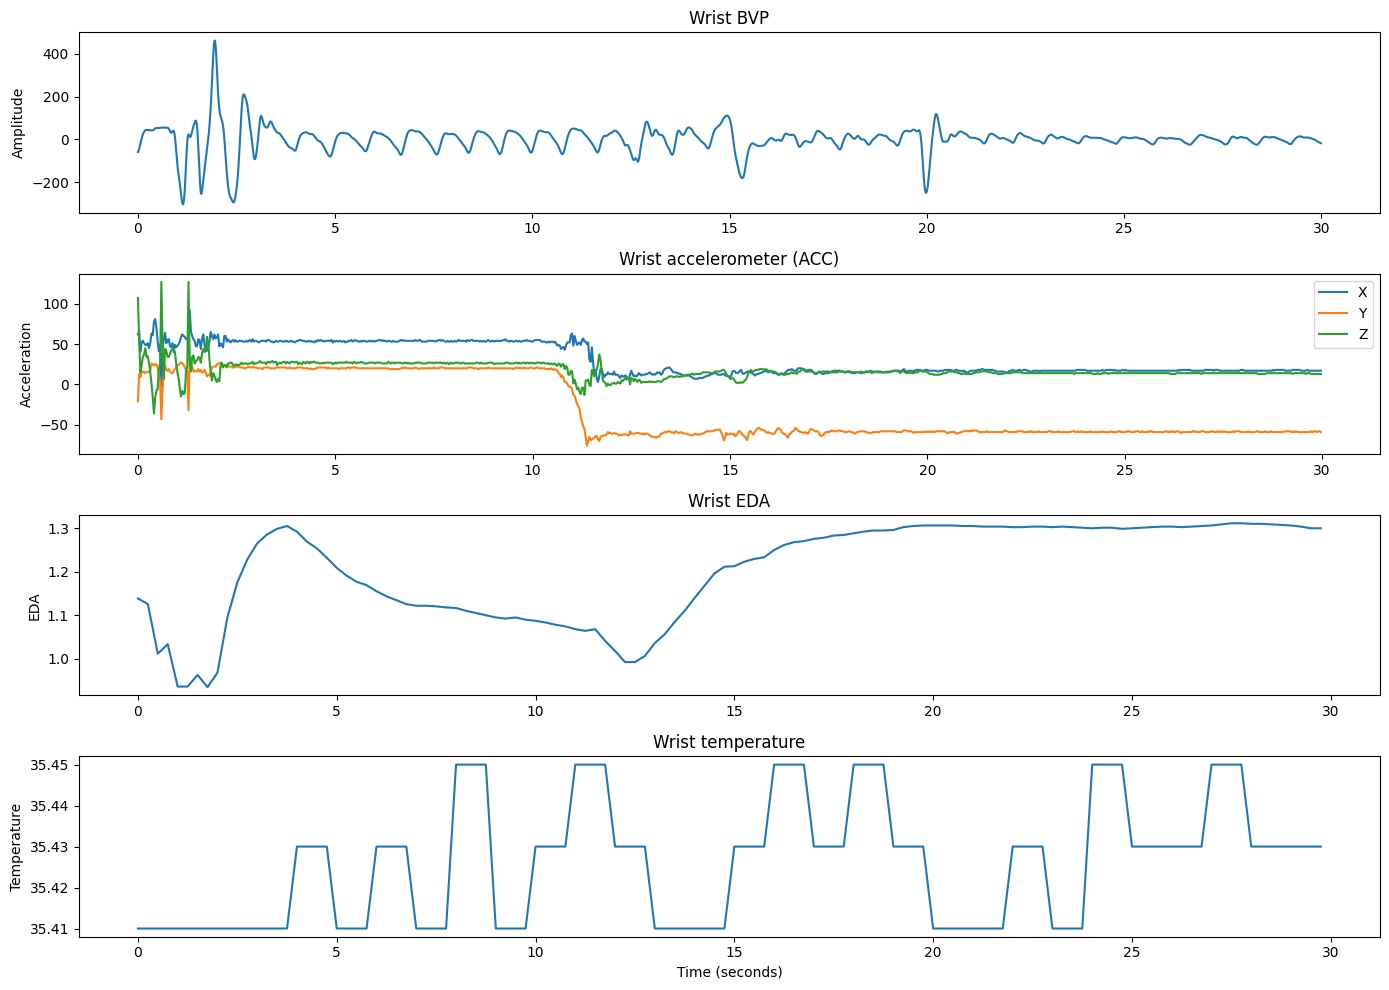

In [10]:
import matplotlib.pyplot as plt
import numpy as np

wrist = data["signal"]["wrist"]

BVP_FS = 64
ACC_FS = 32
EDA_FS = 4
TEMP_FS = 4
LABEL_FS = 700

bvp = np.asarray(wrist["BVP"]).squeeze()
acc = np.asarray(wrist["ACC"])
eda = np.asarray(wrist["EDA"]).squeeze()
temp = np.asarray(wrist["TEMP"]).squeeze()

if acc.ndim == 2 and acc.shape[1] != 3 and acc.shape[0] == 3:
    acc = acc.T

print("Signal duration estimates:")
print(f"BVP:  {len(bvp) / BVP_FS / 60:.2f} minutes")
print(f"ACC:  {len(acc) / ACC_FS / 60:.2f} minutes")
print(f"EDA:  {len(eda) / EDA_FS / 60:.2f} minutes")
print(f"TEMP: {len(temp) / TEMP_FS / 60:.2f} minutes")
print(f"Labels: {len(labels) / LABEL_FS / 60:.2f} minutes")

# Plot the first 30 seconds
seconds = 30

fig, axes = plt.subplots(4, 1, figsize=(14, 10))

axes[0].plot(np.arange(min(len(bvp), seconds * BVP_FS)) / BVP_FS,
             bvp[:seconds * BVP_FS])
axes[0].set_title("Wrist BVP")
axes[0].set_ylabel("Amplitude")

for i, axis_name in enumerate(["X", "Y", "Z"]):
    axes[1].plot(
        np.arange(min(len(acc), seconds * ACC_FS)) / ACC_FS,
        acc[:seconds * ACC_FS, i],
        label=axis_name
    )
axes[1].set_title("Wrist accelerometer (ACC)")
axes[1].set_ylabel("Acceleration")
axes[1].legend()

axes[2].plot(np.arange(min(len(eda), seconds * EDA_FS)) / EDA_FS,
             eda[:seconds * EDA_FS])
axes[2].set_title("Wrist EDA")
axes[2].set_ylabel("EDA")

axes[3].plot(np.arange(min(len(temp), seconds * TEMP_FS)) / TEMP_FS,
             temp[:seconds * TEMP_FS])
axes[3].set_title("Wrist temperature")
axes[3].set_ylabel("Temperature")
axes[3].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

In [11]:
# Extract wrist data
wrist = data["signal"]["wrist"]

bvp = np.asarray(wrist["BVP"]).squeeze()
acc = np.asarray(wrist["ACC"])

labels = np.asarray(data["label"]).reshape(-1)

# Ensure ACC has shape (number_of_samples, 3).
if acc.ndim == 2 and acc.shape[0] == 3 and acc.shape[1] != 3:
    acc = acc.T

print("BVP shape:", bvp.shape)
print("ACC shape:", acc.shape)
print("Labels shape:", labels.shape)

print("\nRecording duration estimates:")
print(f"BVP: {len(bvp) / 64 / 60:.2f} minutes")
print(f"ACC: {len(acc) / 32 / 60:.2f} minutes")
print(f"Labels: {len(labels) / 700 / 60:.2f} minutes")

print("\nLabel values and counts:")
values, counts = np.unique(labels, return_counts=True)

label_names = {
    0: "Transient/other",
    1: "Baseline",
    2: "Stress",
    3: "Amusement",
    4: "Meditation"
}

for value, count in zip(values, counts):
    print(
        f"Label {value} ({label_names.get(int(value), 'Other')}): "
        f"{count:,} samples"
    )

BVP shape: (389056,)
ACC shape: (194528, 3)
Labels shape: (4255300,)

Recording duration estimates:
BVP: 101.32 minutes
ACC: 101.32 minutes
Labels: 101.32 minutes

Label values and counts:
Label 0 (Transient/other): 2,142,701 samples
Label 1 (Baseline): 800,800 samples
Label 2 (Stress): 430,500 samples
Label 3 (Amusement): 253,400 samples
Label 4 (Meditation): 537,599 samples
Label 6 (Other): 45,500 samples
Label 7 (Other): 44,800 samples


# Plot 30-second baseline and stress samples

Baseline sample starts at: 307 seconds
Stress sample starts at: 2274 seconds


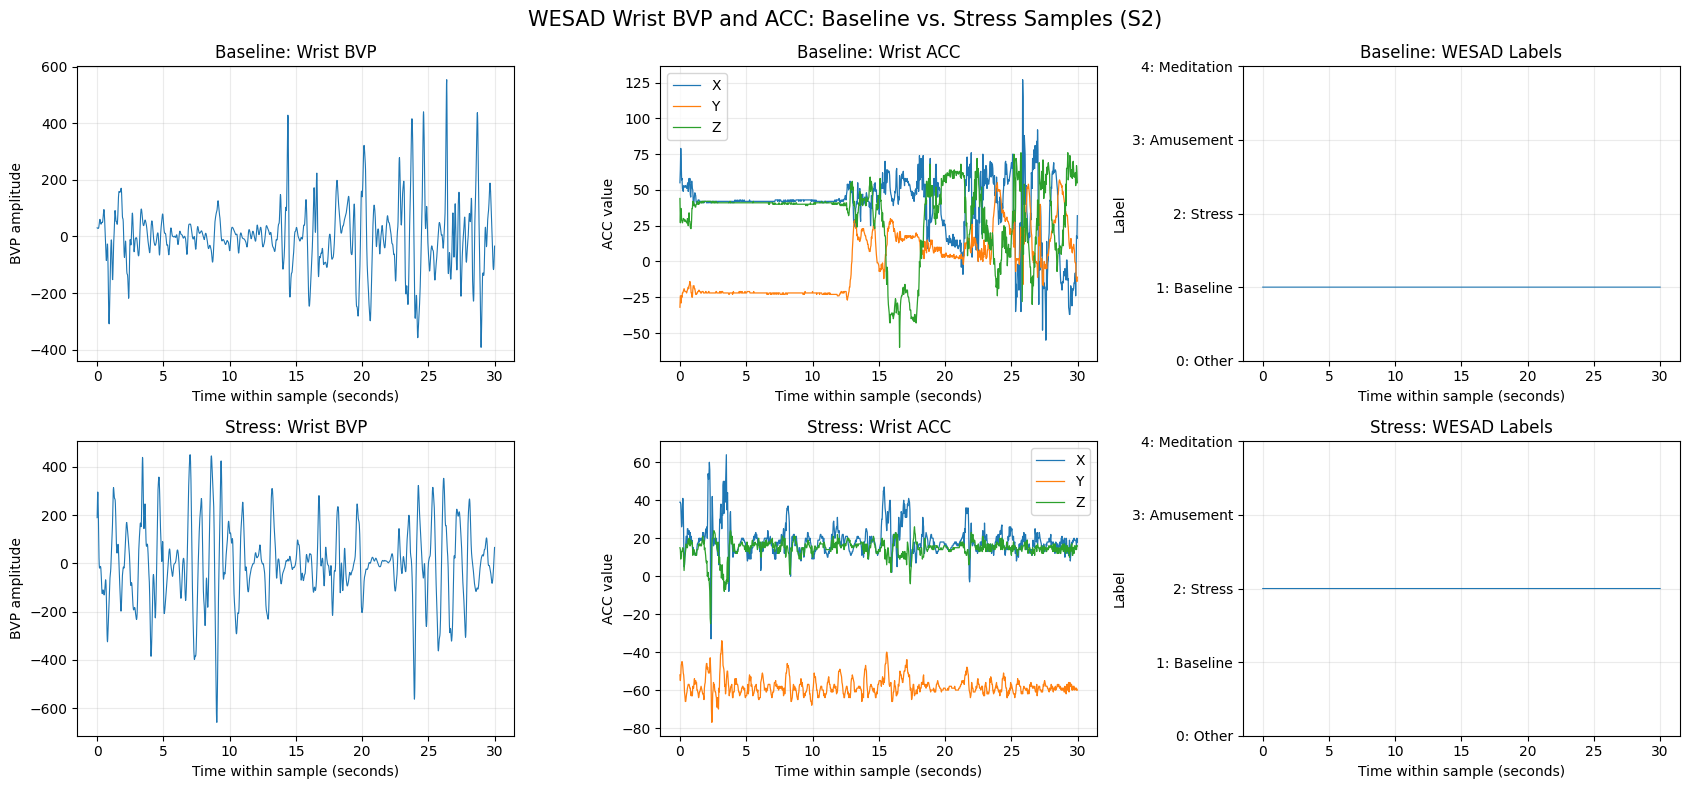


Plot saved to: /content/S2_wrist_BVP_ACC_sample.png


In [12]:
# Standard WESAD wrist and label sampling rates.
BVP_FS = 64
ACC_FS = 32
LABEL_FS = 700

WINDOW_SECONDS = 30

# Make sure both sensors and labels cover the selected interval.
common_duration = min(
    len(bvp) / BVP_FS,
    len(acc) / ACC_FS,
    len(labels) / LABEL_FS
)

# Calculate the most common label within each whole second.
usable_seconds = int(common_duration)

label_blocks = labels[:usable_seconds * LABEL_FS].astype(int)
label_blocks = label_blocks.reshape(usable_seconds, LABEL_FS)

labels_per_second = np.empty(usable_seconds, dtype=int)

for i, block in enumerate(label_blocks):
    vals, cnts = np.unique(block, return_counts=True)
    labels_per_second[i] = vals[np.argmax(cnts)]


def find_label_segment(target_label, duration=WINDOW_SECONDS):
    """Find a continuous interval whose dominant label is the target."""
    if len(labels_per_second) < duration:
        return None

    for start in range(len(labels_per_second) - duration + 1):
        segment = labels_per_second[start:start + duration]

        if np.all(segment == target_label):
            return start

    return None


baseline_start = find_label_segment(1)
stress_start = find_label_segment(2)

print("Baseline sample starts at:", baseline_start, "seconds")
print("Stress sample starts at:", stress_start, "seconds")

if baseline_start is None:
    print("No continuous 30-second baseline segment found.")

if stress_start is None:
    print("No continuous 30-second stress segment found.")

# Plot both conditions in separate rows.
conditions = [
    ("Baseline", 1, baseline_start),
    ("Stress", 2, stress_start)
]

fig, axes = plt.subplots(2, 3, figsize=(17, 8))

for row, (condition_name, target_label, start_sec) in enumerate(conditions):

    if start_sec is None:
        for ax in axes[row]:
            ax.set_visible(False)
        continue

    end_sec = start_sec + WINDOW_SECONDS

    # BVP segment.
    b0 = int(start_sec * BVP_FS)
    b1 = int(end_sec * BVP_FS)
    bvp_segment = bvp[b0:b1]
    t_bvp = np.arange(len(bvp_segment)) / BVP_FS

    axes[row, 0].plot(t_bvp, bvp_segment, linewidth=0.8)
    axes[row, 0].set_title(f"{condition_name}: Wrist BVP")
    axes[row, 0].set_xlabel("Time within sample (seconds)")
    axes[row, 0].set_ylabel("BVP amplitude")
    axes[row, 0].grid(alpha=0.25)

    # Three accelerometer axes.
    a0 = int(start_sec * ACC_FS)
    a1 = int(end_sec * ACC_FS)
    acc_segment = acc[a0:a1, :3]
    t_acc = np.arange(len(acc_segment)) / ACC_FS

    for axis_index, axis_name in enumerate(["X", "Y", "Z"]):
        axes[row, 1].plot(
            t_acc,
            acc_segment[:, axis_index],
            label=axis_name,
            linewidth=0.9
        )

    axes[row, 1].set_title(f"{condition_name}: Wrist ACC")
    axes[row, 1].set_xlabel("Time within sample (seconds)")
    axes[row, 1].set_ylabel("ACC value")
    axes[row, 1].legend()
    axes[row, 1].grid(alpha=0.25)

    # Plot the original labels for the same interval.
    l0 = int(start_sec * LABEL_FS)
    l1 = int(end_sec * LABEL_FS)
    label_segment = labels[l0:l1]
    t_label = np.arange(len(label_segment)) / LABEL_FS

    axes[row, 2].step(
        t_label,
        label_segment,
        where="post",
        linewidth=0.8
    )
    axes[row, 2].set_title(f"{condition_name}: WESAD Labels")
    axes[row, 2].set_xlabel("Time within sample (seconds)")
    axes[row, 2].set_ylabel("Label")
    axes[row, 2].set_yticks([0, 1, 2, 3, 4])
    axes[row, 2].set_yticklabels([
        "0: Other",
        "1: Baseline",
        "2: Stress",
        "3: Amusement",
        "4: Meditation"
    ])
    axes[row, 2].grid(alpha=0.25)

plt.suptitle(
    "WESAD Wrist BVP and ACC: Baseline vs. Stress Samples (S2)",
    fontsize=15
)
plt.tight_layout()

plot_path = "/content/S2_wrist_BVP_ACC_sample.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("\nPlot saved to:", plot_path)

# Check how many participants you extracted

In [ ]:
import os
import glob

pkl_files = sorted(
    glob.glob("/content/WESAD_pkl/S*.pkl")
)

print("Number of participant files:", len(pkl_files))

for path in pkl_files:
    print(os.path.basename(path))

if len(pkl_files) < 5:
    print(
        "\nCheck the extraction before proceeding. "
        "The standard WESAD release contains 15 participants."
    )

Number of participant files: 15
S10.pkl
S11.pkl
S13.pkl
S14.pkl
S15.pkl
S16.pkl
S17.pkl
S2.pkl
S3.pkl
S4.pkl
S5.pkl
S6.pkl
S7.pkl
S8.pkl
S9.pkl


# Extract BVP and ACC features from all participants

In [13]:
import os
import glob
import pickle
import numpy as np
import pandas as pd

from scipy.signal import welch

# Sampling rates for standard WESAD wrist signals
BVP_FS = 64
ACC_FS = 32
LABEL_FS = 700

WINDOW_SEC = 10
MIN_LABEL_PURITY = 0.80

# Verify that the participant files exist
pkl_files = sorted(glob.glob("/content/WESAD_pkl/S*.pkl"))

if len(pkl_files) < 5:
    raise RuntimeError(
        f"Only {len(pkl_files)} participant files found. "
        "Please finish extracting the participant files first."
    )


def statistics_features(x, prefix):
    """Basic statistical features from a signal window."""
    x = np.asarray(x, dtype=float).reshape(-1)
    x = x[np.isfinite(x)]

    if len(x) == 0:
        return {}

    features = {
        f"{prefix}_mean": np.mean(x),
        f"{prefix}_std": np.std(x),
        f"{prefix}_median": np.median(x),
        f"{prefix}_min": np.min(x),
        f"{prefix}_max": np.max(x),
        f"{prefix}_range": np.ptp(x),
        f"{prefix}_rms": np.sqrt(np.mean(x**2)),
        f"{prefix}_iqr": (
            np.percentile(x, 75) - np.percentile(x, 25)
        ),
    }

    if len(x) > 1:
        features[f"{prefix}_diff_std"] = np.std(np.diff(x))

    return features


def bvp_features(signal):
    """Extract statistical and spectral features from wrist BVP."""
    x = np.asarray(signal, dtype=float).reshape(-1)

    features = statistics_features(x, "bvp")

    # Estimate the dominant frequency within a pulse-related band.
    # This is an exploratory feature, not a validated heart-rate estimate.
    if len(x) >= 32 and np.all(np.isfinite(x)):
        freqs, power = welch(
            x,
            fs=BVP_FS,
            nperseg=min(256, len(x))
        )

        mask = (freqs >= 0.5) & (freqs <= 4.0)

        if np.any(mask):
            band_freqs = freqs[mask]
            band_power = power[mask]

            peak_index = np.argmax(band_power)
            frequency_step = freqs[1] - freqs[0]

            features["bvp_peak_frequency_hz"] = band_freqs[peak_index]
            features["bvp_peak_frequency_bpm_equivalent"] = (
                band_freqs[peak_index] * 60
            )
            features["bvp_band_power"] = (
                np.sum(band_power) * frequency_step
            )

    return features


def acc_features(signal):
    """Extract movement features from three-axis wrist ACC."""
    x = np.asarray(signal, dtype=float)

    # Make the data shape: samples x 3 axes.
    if x.ndim == 2 and x.shape[0] == 3 and x.shape[1] != 3:
        x = x.T

    if x.ndim != 2 or x.shape[1] < 3:
        raise ValueError(f"Unexpected ACC shape: {x.shape}")

    x = x[:, :3]

    features = {}

    for i, axis in enumerate(["x", "y", "z"]):
        features.update(
            statistics_features(x[:, i], f"acc_{axis}")
        )

    # Overall acceleration magnitude
    magnitude = np.linalg.norm(x, axis=1)

    features.update(
        statistics_features(magnitude, "acc_magnitude")
    )

    # A simple measure of how rapidly the magnitude changes
    if len(magnitude) > 1:
        features["acc_magnitude_diff_std"] = np.std(
            np.diff(magnitude) * ACC_FS
        )

    # Mean sum of absolute axis values
    features["acc_signal_magnitude_mean"] = np.mean(
        np.sum(np.abs(x), axis=1)
    )

    return features


def extract_subject(data, subject):
    """Extract aligned BVP and ACC features from one participant."""
    wrist = data["signal"]["wrist"]

    bvp = np.asarray(wrist["BVP"]).squeeze()
    acc = np.asarray(wrist["ACC"])

    labels = np.asarray(data["label"]).reshape(-1)

    if acc.ndim == 2 and acc.shape[0] == 3 and acc.shape[1] != 3:
        acc = acc.T

    if bvp.ndim != 1:
        raise ValueError(f"{subject}: unexpected BVP shape {bvp.shape}")

    if acc.ndim != 2 or acc.shape[1] < 3:
        raise ValueError(f"{subject}: unexpected ACC shape {acc.shape}")

    # Use only the time range shared by both sensors and the labels.
    duration = min(
        len(bvp) / BVP_FS,
        len(acc) / ACC_FS,
        len(labels) / LABEL_FS
    )

    number_of_windows = int(duration // WINDOW_SEC)

    rows_bvp = []
    rows_acc = []
    rows_combined = []

    for w in range(number_of_windows):
        start_sec = w * WINDOW_SEC
        end_sec = start_sec + WINDOW_SEC

        # Corresponding slices from each stream's own sampling rate
        b0 = int(start_sec * BVP_FS)
        b1 = int(end_sec * BVP_FS)

        a0 = int(start_sec * ACC_FS)
        a1 = int(end_sec * ACC_FS)

        l0 = int(start_sec * LABEL_FS)
        l1 = int(end_sec * LABEL_FS)

        bvp_window = bvp[b0:b1]
        acc_window = acc[a0:a1]
        label_window = labels[l0:l1]

        if (
            len(bvp_window) == 0
            or len(acc_window) == 0
            or len(label_window) == 0
        ):
            continue

        values, counts = np.unique(label_window, return_counts=True)
        dominant_label = int(values[np.argmax(counts)])
        purity = float(np.max(counts) / len(label_window))

        # Keep only baseline (1) and stress (2) windows
        # with at least 80% agreement in their labels.
        if dominant_label not in (1, 2):
            continue

        if purity < MIN_LABEL_PURITY:
            continue

        metadata = {
            "subject": subject,
            "window_start_sec": start_sec,
            "wesad_label": dominant_label,
            "target": 0 if dominant_label == 1 else 1,
            "target_name": (
                "baseline" if dominant_label == 1 else "stress"
            ),
            "label_purity": purity
        }

        bf = bvp_features(bvp_window)
        af = acc_features(acc_window)

        rows_bvp.append({**metadata, **bf})
        rows_acc.append({**metadata, **af})
        rows_combined.append({**metadata, **bf, **af})

    return rows_bvp, rows_acc, rows_combined


# Process participants one at a time to limit memory use.
all_bvp = []
all_acc = []
all_combined = []

for i, path in enumerate(pkl_files, start=1):
    subject = os.path.splitext(os.path.basename(path))[0]
    print(f"Processing {subject} ({i}/{len(pkl_files)})...")

    with open(path, "rb") as f:
        participant_data = pickle.load(f, encoding="latin1")

    rows_b, rows_a, rows_c = extract_subject(
        participant_data, subject
    )

    all_bvp.extend(rows_b)
    all_acc.extend(rows_a)
    all_combined.extend(rows_c)

    del participant_data

# Save three aligned datasets.
datasets = {
    "BVP_only": all_bvp,
    "ACC_only": all_acc,
    "BVP_ACC_combined": all_combined
}

for name, rows in datasets.items():
    df = pd.DataFrame(rows)

    output_path = f"/content/features_{name}.csv"
    df.to_csv(output_path, index=False)

    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Participants:", df["subject"].nunique() if not df.empty else 0)
    print("Saved to:", output_path)

    if not df.empty:
        print("Class counts:")
        print(df["target_name"].value_counts())

Processing S10 (1/15)...
Processing S11 (2/15)...
Processing S13 (3/15)...
Processing S14 (4/15)...
Processing S15 (5/15)...
Processing S16 (6/15)...
Processing S17 (7/15)...
Processing S2 (8/15)...
Processing S3 (9/15)...
Processing S4 (10/15)...
Processing S5 (11/15)...
Processing S6 (12/15)...
Processing S7 (13/15)...
Processing S8 (14/15)...
Processing S9 (15/15)...

BVP_only
Shape: (2733, 18)
Participants: 15
Saved to: /content/features_BVP_only.csv
Class counts:
target_name
baseline    1749
stress       984
Name: count, dtype: int64

ACC_only
Shape: (2733, 43)
Participants: 15
Saved to: /content/features_ACC_only.csv
Class counts:
target_name
baseline    1749
stress       984
Name: count, dtype: int64

BVP_ACC_combined
Shape: (2733, 55)
Participants: 15
Saved to: /content/features_BVP_ACC_combined.csv
Class counts:
target_name
baseline    1749
stress       984
Name: count, dtype: int64


# Verify the feature datasets

In [14]:
df = pd.read_csv("/content/features_BVP_ACC_combined.csv")

print("Dataset dimensions:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nClass distribution:")
display(df["target_name"].value_counts())

print("\nWindows per participant:")
display(df.groupby(["subject", "target_name"]).size().unstack(fill_value=0))

Dataset dimensions: (2733, 55)

First five rows:


,subject,window_start_sec,wesad_label,target,target_name,label_purity,bvp_mean,bvp_std,bvp_median,bvp_min,...,acc_magnitude_mean,acc_magnitude_std,acc_magnitude_median,acc_magnitude_min,acc_magnitude_max,acc_magnitude_range,acc_magnitude_rms,acc_magnitude_iqr,acc_magnitude_diff_std,acc_signal_magnitude_mean
0,S10,100,1,0,baseline,1.0,0.720672,81.039538,-2.655,-247.22,...,63.007880,2.306408,63.000000,54.055527,74.330344,20.274817,63.050079,0.850674,55.394922,88.425000
1,S10,110,1,0,baseline,1.0,-0.147172,36.581211,1.095,-138.13,...,62.813160,0.415440,62.777384,60.547502,64.311741,3.764239,62.814534,0.206924,17.140052,88.965625
2,S10,120,1,0,baseline,1.0,1.528188,79.957260,6.175,-264.71,...,63.023114,3.099338,62.777384,51.351728,83.030115,31.678387,63.099277,0.656217,68.290433,88.437500
3,S10,130,1,0,baseline,1.0,-1.729531,84.188990,-0.300,-211.67,...,63.056855,2.015236,63.206012,47.686476,73.164199,25.477723,63.089049,0.676395,49.502896,86.784375
4,S10,140,1,0,baseline,1.0,1.006047,12.044723,3.940,-29.01,...,62.875737,0.322773,62.721607,61.725197,64.645185,2.919988,62.876566,0.484405,11.864200,88.425000



Class distribution:


,count
target_name,
baseline,1749
stress,984



Windows per participant:


target_name,baseline,stress
subject,,
S10,117,71
S11,117,67
S13,117,66
S14,117,67
S15,117,68
S16,118,67
S17,117,71
S2,114,61
S3,113,63


# 2. Train Random Forest, SVM, XGBoost Models on three dataset

This is an attempt, without using self-collected data

In [15]:
%pip -q install xgboost

## 2.1. Load and compare the three datasets.

In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

DATA_PATHS = {
    "BVP only": "/content/features_BVP_only.csv",
    "ACC only": "/content/features_ACC_only.csv",
    "BVP + ACC": "/content/features_BVP_ACC_combined.csv"
}

# Check that all three datasets exist.
for name, path in DATA_PATHS.items():
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing file for {name}: {path}\n"
            "Please run the previous feature-extraction cell first."
        )

datasets = {}

for name, path in DATA_PATHS.items():
    df = pd.read_csv(path)

    required = {
        "subject", "window_start_sec", "target"
    }

    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{name} is missing columns: {missing}")

    df["subject"] = df["subject"].astype(str)
    df["window_start_sec"] = pd.to_numeric(
        df["window_start_sec"], errors="coerce"
    )
    df["target"] = pd.to_numeric(df["target"], errors="coerce")

    df = df.dropna(
        subset=["subject", "window_start_sec", "target"]
    ).copy()

    df["target"] = df["target"].astype(int)

    # Keep only the two desired classes:
    # 0 = baseline, 1 = stress.
    df = df[df["target"].isin([0, 1])].copy()

    datasets[name] = df

# Use only windows present in all three datasets.
key_columns = ["subject", "window_start_sec", "target"]

key_sets = []
for df in datasets.values():
    keys = set(
        (
            str(subject),
            float(start),
            int(target)
        )
        for subject, start, target
        in df[key_columns].itertuples(index=False, name=None)
    )
    key_sets.append(keys)

common_keys = set.intersection(*key_sets)

if not common_keys:
    raise ValueError(
        "No common windows were found across the three datasets. "
        "Check the previous feature-extraction output."
    )

for name in datasets:
    df = datasets[name].copy()

    row_keys = [
        (str(s), float(t), int(y))
        for s, t, y
        in df[key_columns].itertuples(index=False, name=None)
    ]

    df = df.loc[
        [key in common_keys for key in row_keys]
    ].copy()

    # Exclude metadata and labels from model inputs.
    metadata = {
        "subject",
        "window_start_sec",
        "wesad_label",
        "target",
        "target_name",
        "label_purity"
    }

    feature_columns = [
        col for col in df.columns
        if col not in metadata
        and pd.api.types.is_numeric_dtype(df[col])
    ]

    if not feature_columns:
        raise ValueError(f"No numeric features found in {name}.")

    # Convert infinite values to missing values.
    df[feature_columns] = df[feature_columns].replace(
        [np.inf, -np.inf], np.nan
    )

    # Remove features that contain no valid values at all.
    feature_columns = [
        col for col in feature_columns
        if df[col].notna().any()
    ]

    if not feature_columns:
        raise ValueError(f"All features are empty in {name}.")

    df = df.reset_index(drop=True)
    datasets[name] = df

    print(f"\n{name}")
    print("Rows:", len(df))
    print("Participants:", df["subject"].nunique())
    print("Features:", len(feature_columns))
    print("Baseline windows:", int((df["target"] == 0).sum()))
    print("Stress windows:", int((df["target"] == 1).sum()))


BVP only
Rows: 2733
Participants: 15
Features: 12
Baseline windows: 1749
Stress windows: 984

ACC only
Rows: 2733
Participants: 15
Features: 37
Baseline windows: 1749
Stress windows: 984

BVP + ACC
Rows: 2733
Participants: 15
Features: 49
Baseline windows: 1749
Stress windows: 984


## 2.2. Train the nine models
We’ll use five-fold group cross-validation. The data is split by participant, rather than by individual windows.

The models use these starting settings:

- Random Forest: 300 trees.

- SVM: RBF kernel, with standardized features.

- XGBoost: 300 boosting rounds with a learning rate of 0.05.

Missing feature values are imputed within each training fold, avoiding the use of test-fold information during preprocessing.

In [17]:
RANDOM_STATE = 42

# Use up to five folds, depending on the number of participants.
all_subjects = sorted(
    set(
        subject
        for df in datasets.values()
        for subject in df["subject"].unique()
    )
)

if len(all_subjects) < 2:
    raise ValueError("At least two participants are needed.")

N_SPLITS = min(5, len(all_subjects))

print("Participants:", len(all_subjects))
print("Cross-validation folds:", N_SPLITS)


def get_feature_columns(df):
    metadata = {
        "subject",
        "window_start_sec",
        "wesad_label",
        "target",
        "target_name",
        "label_purity"
    }

    return [
        col for col in df.columns
        if col not in metadata
        and pd.api.types.is_numeric_dtype(df[col])
    ]


def build_models(y_train):
    """Build fresh pipelines for the current training fold."""

    # XGBoost weighting can help when class counts are unequal.
    n_negative = max(1, int(np.sum(y_train == 0)))
    n_positive = max(1, int(np.sum(y_train == 1)))
    scale_pos_weight = n_negative / n_positive

    return {
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced_subsample",
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ]),

        "SVM": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", SVC(
                kernel="rbf",
                C=1.0,
                gamma="scale",
                class_weight="balanced"
            ))
        ]),

        "XGBoost": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", XGBClassifier(
                objective="binary:logistic",
                eval_metric="logloss",
                n_estimators=300,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_lambda=1.0,
                scale_pos_weight=scale_pos_weight,
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ])
    }


def evaluate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "Stress precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Stress recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Stress F1": f1_score(
            y_true, y_pred, zero_division=0
        )
    }


# Generate the same held-out participant groups for every dataset.
subject_array = np.array(all_subjects)

splitter = GroupKFold(n_splits=N_SPLITS)

subject_folds = list(
    splitter.split(
        np.zeros((len(subject_array), 1)),
        groups=subject_array
    )
)

summary_rows = []
fold_rows = []
prediction_frames = []
confusion_matrices = {}

for dataset_name, df in datasets.items():

    feature_columns = get_feature_columns(df)

    X = df[feature_columns]
    y = df["target"].to_numpy()
    groups = df["subject"].to_numpy()

    print(f"\n{'=' * 65}")
    print(f"Dataset: {dataset_name}")
    print(f"Rows: {len(df)} | Features: {len(feature_columns)}")
    print(f"{'=' * 65}")

    for model_name in [
        "Random Forest",
        "SVM",
        "XGBoost"
    ]:

        print(f"\nTraining {model_name}...")

        # Each row receives one prediction from a model
        # that did not train on that row's participant.
        oof_predictions = np.full(len(df), -1, dtype=int)
        current_fold_metrics = []

        for fold_number, (train_sub_idx, test_sub_idx) in enumerate(
            subject_folds, start=1
        ):

            train_subjects = set(subject_array[train_sub_idx])
            test_subjects = set(subject_array[test_sub_idx])

            train_mask = np.isin(groups, list(train_subjects))
            test_mask = np.isin(groups, list(test_subjects))

            X_train = X.loc[train_mask]
            y_train = y[train_mask]

            X_test = X.loc[test_mask]
            y_test = y[test_mask]

            if len(np.unique(y_train)) < 2:
                raise ValueError(
                    f"{model_name}, {dataset_name}, fold {fold_number}: "
                    "training data contains only one class."
                )

            models = build_models(y_train)
            model = models[model_name]

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test).astype(int)

            test_positions = np.flatnonzero(test_mask)
            oof_predictions[test_positions] = y_pred

            fold_result = evaluate_metrics(y_test, y_pred)

            fold_rows.append({
                "Dataset": dataset_name,
                "Model": model_name,
                "Fold": fold_number,
                "Test participants": ", ".join(
                    sorted(test_subjects)
                ),
                **fold_result
            })

            current_fold_metrics.append(fold_result)

            print(
                f"  Fold {fold_number}/{N_SPLITS}: "
                f"F1={fold_result['Stress F1']:.3f}; "
                f"balanced accuracy="
                f"{fold_result['Balanced accuracy']:.3f}; "
                f"test participants={len(test_subjects)}"
            )

        if np.any(oof_predictions == -1):
            raise RuntimeError(
                "Some rows did not receive an out-of-fold prediction."
            )

        # Overall out-of-fold performance across all held-out participants.
        overall = evaluate_metrics(y, oof_predictions)

        fold_f1 = [
            result["Stress F1"]
            for result in current_fold_metrics
        ]

        summary_rows.append({
            "Dataset": dataset_name,
            "Model": model_name,
            **overall,
            "Mean fold F1": np.mean(fold_f1),
            "SD fold F1": (
                np.std(fold_f1, ddof=1)
                if len(fold_f1) > 1 else 0.0
            ),
            "Participants": df["subject"].nunique(),
            "Windows": len(df),
            "Features": len(feature_columns)
        })

        cm = confusion_matrix(
            y,
            oof_predictions,
            labels=[0, 1]
        )

        confusion_matrices[(dataset_name, model_name)] = cm

        prediction_frames.append(pd.DataFrame({
            "dataset": dataset_name,
            "model": model_name,
            "subject": df["subject"],
            "window_start_sec": df["window_start_sec"],
            "y_true": y,
            "y_pred": oof_predictions
        }))

        print(
            f"  Overall out-of-fold F1: {overall['Stress F1']:.3f}"
        )

Participants: 15
Cross-validation folds: 5

Dataset: BVP only
Rows: 2733 | Features: 12

Training Random Forest...
  Fold 1/5: F1=0.465; balanced accuracy=0.621; test participants=3
  Fold 2/5: F1=0.692; balanced accuracy=0.761; test participants=3
  Fold 3/5: F1=0.613; balanced accuracy=0.698; test participants=3
  Fold 4/5: F1=0.646; balanced accuracy=0.734; test participants=3
  Fold 5/5: F1=0.641; balanced accuracy=0.704; test participants=3
  Overall out-of-fold F1: 0.616

Training SVM...
  Fold 1/5: F1=0.579; balanced accuracy=0.668; test participants=3
  Fold 2/5: F1=0.758; balanced accuracy=0.812; test participants=3
  Fold 3/5: F1=0.673; balanced accuracy=0.741; test participants=3
  Fold 4/5: F1=0.735; balanced accuracy=0.791; test participants=3
  Fold 5/5: F1=0.634; balanced accuracy=0.683; test participants=3
  Overall out-of-fold F1: 0.673

Training XGBoost...
  Fold 1/5: F1=0.533; balanced accuracy=0.645; test participants=3
  Fold 2/5: F1=0.721; balanced accuracy=0.782;

## 2.3. Compare model performance

In [18]:
results_df = pd.DataFrame(summary_rows)

metric_columns = [
    "Accuracy",
    "Balanced accuracy",
    "Stress precision",
    "Stress recall",
    "Stress F1",
    "Mean fold F1",
    "SD fold F1"
]

print("Model comparison:")
display(
    results_df
    .sort_values("Stress F1", ascending=False)
    .round(3)
)

results_path = "/content/WESAD_model_comparison.csv"
fold_path = "/content/WESAD_model_fold_results.csv"
predictions_path = "/content/WESAD_oof_predictions.csv"

results_df.to_csv(results_path, index=False)
pd.DataFrame(fold_rows).to_csv(fold_path, index=False)

predictions_df = pd.concat(
    prediction_frames, ignore_index=True
)
predictions_df.to_csv(predictions_path, index=False)

print("\nSaved:")
print(results_path)
print(fold_path)
print(predictions_path)

Model comparison:


,Dataset,Model,Accuracy,Balanced accuracy,Stress precision,Stress recall,Stress F1,Mean fold F1,SD fold F1,Participants,Windows,Features
7,BVP + ACC,SVM,0.763,0.749,0.663,0.697,0.680,0.689,0.095,15,2733,49
1,BVP only,SVM,0.727,0.739,0.591,0.782,0.673,0.676,0.073,15,2733,12
8,BVP + ACC,XGBoost,0.773,0.743,0.704,0.637,0.669,0.667,0.079,15,2733,49
2,BVP only,XGBoost,0.730,0.727,0.607,0.714,0.656,0.655,0.078,15,2733,12
5,ACC only,XGBoost,0.761,0.722,0.703,0.582,0.637,0.641,0.073,15,2733,37
0,BVP only,Random Forest,0.735,0.704,0.645,0.590,0.616,0.611,0.087,15,2733,12
4,ACC only,SVM,0.716,0.691,0.607,0.601,0.604,0.610,0.140,15,2733,37
6,BVP + ACC,Random Forest,0.725,0.667,0.671,0.462,0.548,0.537,0.063,15,2733,49
3,ACC only,Random Forest,0.698,0.631,0.629,0.392,0.483,0.468,0.135,15,2733,37



Saved:
/content/WESAD_model_comparison.csv
/content/WESAD_model_fold_results.csv
/content/WESAD_oof_predictions.csv


## 2.4 Confusion Matrices

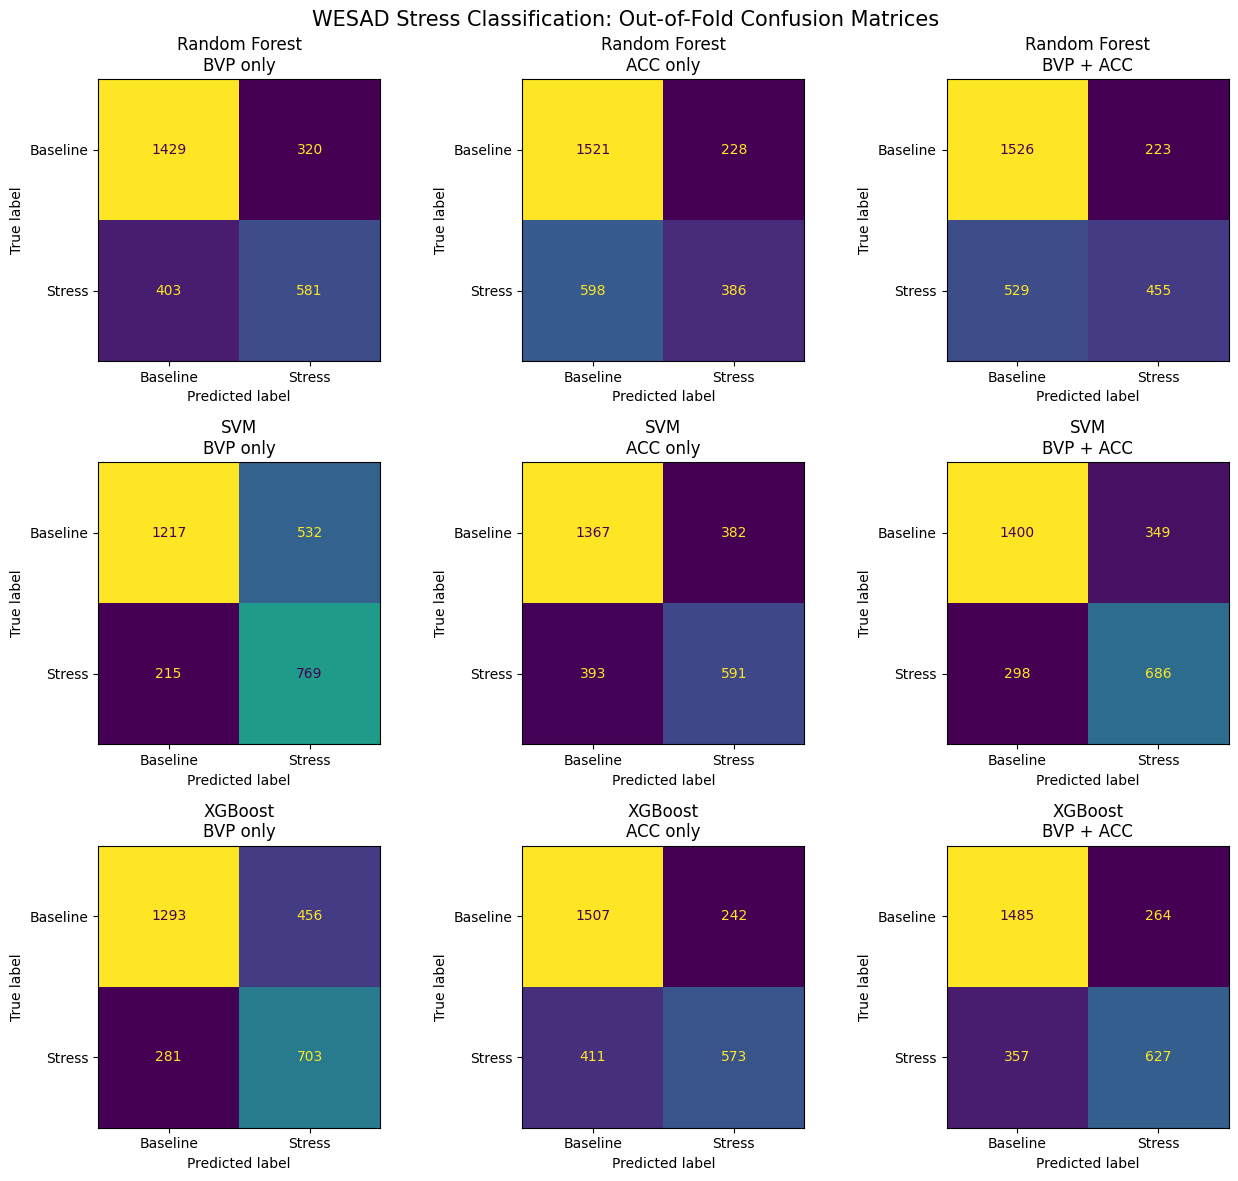

Saved plot: /content/WESAD_confusion_matrices.png


In [19]:
dataset_names = [
    "BVP only",
    "ACC only",
    "BVP + ACC"
]

model_names = [
    "Random Forest",
    "SVM",
    "XGBoost"
]

fig, axes = plt.subplots(3, 3, figsize=(13, 12))

for row, model_name in enumerate(model_names):
    for col, dataset_name in enumerate(dataset_names):

        ax = axes[row, col]

        cm = confusion_matrices[(dataset_name, model_name)]

        display = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Baseline", "Stress"]
        )

        display.plot(
            ax=ax,
            colorbar=False,
            values_format="d"
        )

        ax.set_title(f"{model_name}\n{dataset_name}")

plt.suptitle(
    "WESAD Stress Classification: Out-of-Fold Confusion Matrices",
    fontsize=15
)

plt.tight_layout()

confusion_path = "/content/WESAD_confusion_matrices.png"
plt.savefig(confusion_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved plot:", confusion_path)

#3 Tune the three existing models properly

In [20]:
from IPython.display import display as show_table
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay as CMDisplay



In [22]:
import os
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# -------------------------------------------------------
# 1. Load the three feature datasets
# -------------------------------------------------------

DATA_PATHS = {
    "BVP only": "/content/features_BVP_only.csv",
    "ACC only": "/content/features_ACC_only.csv",
    "BVP + ACC": "/content/features_BVP_ACC_combined.csv"
}

dataframes = {}

for name, path in DATA_PATHS.items():
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing dataset: {path}")

    df = pd.read_csv(path)
    df["subject"] = df["subject"].astype(str)
    df["window_start_sec"] = pd.to_numeric(
        df["window_start_sec"], errors="coerce"
    )
    df["target"] = pd.to_numeric(df["target"], errors="coerce")

    df = df.dropna(
        subset=["subject", "window_start_sec", "target"]
    ).copy()

    df["target"] = df["target"].astype(int)
    df = df[df["target"].isin([0, 1])].copy()

    df["window_start_sec"] = df["window_start_sec"].round(6)
    dataframes[name] = df

# Make sure the three models are compared on the same windows.
key_sets = []

for df in dataframes.values():
    key_sets.append(set(zip(
        df["subject"],
        df["window_start_sec"],
        df["target"]
    )))

common_keys = set.intersection(*key_sets)

if not common_keys:
    raise ValueError("No shared windows across the three datasets.")

for name, df in dataframes.items():
    keys = list(zip(
        df["subject"],
        df["window_start_sec"],
        df["target"]
    ))

    df = df.loc[
        [key in common_keys for key in keys]
    ].copy()

    metadata = {
        "subject", "window_start_sec",
        "wesad_label", "target", "target_name",
        "label_purity"
    }

    feature_columns = [
        c for c in df.columns
        if c not in metadata
        and pd.api.types.is_numeric_dtype(df[c])
    ]

    df[feature_columns] = df[feature_columns].replace(
        [np.inf, -np.inf], np.nan
    )

    feature_columns = [
        c for c in feature_columns
        if df[c].notna().any()
    ]

    dataframes[name] = df.reset_index(drop=True)

# -------------------------------------------------------
# 2. Define models and hyperparameter search spaces
# -------------------------------------------------------

def create_model_and_space(model_name):

    if model_name == "Random Forest":
        model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                random_state=42,
                class_weight="balanced_subsample",
                n_jobs=1
            ))
        ])

        params = {
            "model__n_estimators": [200, 300, 400],
            "model__max_depth": [None, 8, 16, 24],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": ["sqrt", 0.7, 1.0]
        }

    elif model_name == "SVM":
        model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", SVC(class_weight="balanced"))
        ])

        params = {
            "model__kernel": ["rbf"],
            "model__C": [0.1, 1, 10, 100],
            "model__gamma": [
                "scale", "auto", 0.001, 0.01, 0.1
            ]
        }

    elif model_name == "XGBoost":
        model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", XGBClassifier(
                objective="binary:logistic",
                eval_metric="logloss",
                tree_method="hist",
                random_state=42,
                n_jobs=1
            ))
        ])

        params = {
            "model__n_estimators": [100, 200, 300],
            "model__max_depth": [2, 3, 4, 5],
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__subsample": [0.7, 0.85, 1.0],
            "model__colsample_bytree": [0.7, 0.85, 1.0],
            "model__min_child_weight": [1, 3, 5],
            "model__reg_lambda": [1, 5, 10]
        }

    return model, params


# -------------------------------------------------------
# 3. Nested group cross-validation
# -------------------------------------------------------

outer_splits = 5
inner_splits = 3
search_iterations = 4

results = []
predictions = []

for dataset_name, df in dataframes.items():

    metadata = {
        "subject", "window_start_sec",
        "wesad_label", "target", "target_name",
        "label_purity"
    }

    features = sorted([
        c for c in df.columns
        if c not in metadata
        and pd.api.types.is_numeric_dtype(df[c])
        and df[c].notna().any()
    ])

    X = df[features].copy()
    y = df["target"].to_numpy()
    groups = df["subject"].to_numpy()

    n_subjects = len(np.unique(groups))

    if n_subjects < outer_splits:
        raise ValueError(
            f"{dataset_name} has only {n_subjects} participants."
        )

    outer_cv = GroupKFold(n_splits=outer_splits)

    print(
        f"\nDataset: {dataset_name}; "
        f"{len(df)} windows, {len(features)} features, "
        f"{n_subjects} participants"
    )

    for model_name in [
        "Random Forest", "SVM", "XGBoost"
    ]:

        print(f"\nTuning {model_name}...")
        oof_predictions = np.full(len(df), -1, dtype=int)
        fold_scores = []

        for fold, (train_idx, test_idx) in enumerate(
            outer_cv.split(X, y, groups), start=1
        ):

            X_train = X.iloc[train_idx]
            y_train = y[train_idx]
            groups_train = groups[train_idx]

            X_test = X.iloc[test_idx]
            y_test = y[test_idx]

            model, param_space = create_model_and_space(
                model_name
            )

            inner_cv = GroupKFold(n_splits=inner_splits)

            search = RandomizedSearchCV(
                estimator=model,
                param_distributions=param_space,
                n_iter=search_iterations,
                scoring="balanced_accuracy",
                cv=inner_cv,
                random_state=42,
                n_jobs=-1,
                refit=True,
                error_score="raise"
            )

            # Group information is used by the inner CV splitter.
            search.fit(
                X_train,
                y_train,
                groups=groups_train
            )

            y_pred = search.predict(X_test).astype(int)
            oof_predictions[test_idx] = y_pred

            score = balanced_accuracy_score(y_test, y_pred)
            fold_scores.append(score)

            print(
                f"  Outer fold {fold}/{outer_splits}: "
                f"balanced accuracy={score:.3f}"
            )

        # Every sample should have a held-out prediction.
        assert np.all(oof_predictions >= 0)

        results.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y, oof_predictions),
            "Balanced accuracy": balanced_accuracy_score(
                y, oof_predictions
            ),
            "Stress precision": precision_score(
                y, oof_predictions, zero_division=0
            ),
            "Stress recall": recall_score(
                y, oof_predictions, zero_division=0
            ),
            "Stress F1": f1_score(
                y, oof_predictions, zero_division=0
            ),
            "Mean outer-fold balanced accuracy": np.mean(
                fold_scores
            ),
            "SD outer-fold balanced accuracy": np.std(
                fold_scores, ddof=1
            ),
            "Participants": n_subjects,
            "Windows": len(df),
            "Features": len(features)
        })

        predictions.append(pd.DataFrame({
            "dataset": dataset_name,
            "model": model_name,
            "subject": df["subject"].to_numpy(),
            "y_true": y,
            "y_pred": oof_predictions
        }))




Dataset: BVP only; 2733 windows, 12 features, 15 participants

Tuning Random Forest...
  Outer fold 1/5: balanced accuracy=0.787
  Outer fold 2/5: balanced accuracy=0.670
  Outer fold 3/5: balanced accuracy=0.648
  Outer fold 4/5: balanced accuracy=0.747
  Outer fold 5/5: balanced accuracy=0.731

Tuning SVM...
  Outer fold 1/5: balanced accuracy=0.794
  Outer fold 2/5: balanced accuracy=0.667
  Outer fold 3/5: balanced accuracy=0.632
  Outer fold 4/5: balanced accuracy=0.775
  Outer fold 5/5: balanced accuracy=0.835

Tuning XGBoost...
  Outer fold 1/5: balanced accuracy=0.769
  Outer fold 2/5: balanced accuracy=0.676
  Outer fold 3/5: balanced accuracy=0.651
  Outer fold 4/5: balanced accuracy=0.721
  Outer fold 5/5: balanced accuracy=0.733

Dataset: ACC only; 2733 windows, 37 features, 15 participants

Tuning Random Forest...
  Outer fold 1/5: balanced accuracy=0.769
  Outer fold 2/5: balanced accuracy=0.667
  Outer fold 3/5: balanced accuracy=0.616
  Outer fold 4/5: balanced accurac

In [23]:
# -------------------------------------------------------
# 4. Show and save the results
# -------------------------------------------------------

from IPython.display import display as ipy_display

tuned_results = pd.DataFrame(results).sort_values(
    "Balanced accuracy", ascending=False
)

# Display results
ipy_display(tuned_results.round(3))

# Save performance results
tuned_results.to_csv(
    "/content/WESAD_nested_tuned_results.csv",
    index=False
)

# Save held-out predictions
pd.concat(predictions, ignore_index=True).to_csv(
    "/content/WESAD_nested_tuned_predictions.csv",
    index=False
)

print("Saved tuned results and held-out predictions to /content.")

,Dataset,Model,Accuracy,Balanced accuracy,Stress precision,Stress recall,Stress F1,Mean outer-fold balanced accuracy,SD outer-fold balanced accuracy,Participants,Windows,Features
4,ACC only,SVM,0.809,0.810,0.701,0.817,0.755,0.811,0.047,15,2733,37
8,BVP + ACC,XGBoost,0.832,0.800,0.820,0.684,0.746,0.800,0.049,15,2733,49
7,BVP + ACC,SVM,0.810,0.794,0.737,0.737,0.737,0.795,0.053,15,2733,49
6,BVP + ACC,Random Forest,0.783,0.743,0.748,0.600,0.666,0.743,0.087,15,2733,49
1,BVP only,SVM,0.729,0.741,0.593,0.784,0.675,0.741,0.087,15,2733,12
5,ACC only,XGBoost,0.779,0.740,0.736,0.601,0.661,0.740,0.063,15,2733,37
0,BVP only,Random Forest,0.734,0.717,0.624,0.655,0.639,0.717,0.057,15,2733,12
2,BVP only,XGBoost,0.737,0.710,0.640,0.615,0.627,0.710,0.047,15,2733,12
3,ACC only,Random Forest,0.744,0.690,0.701,0.501,0.584,0.691,0.064,15,2733,37


Saved tuned results and held-out predictions to /content.


# Diagnostic cell — WESAD signal scales

# check the actual WESAD ACC scale

In [24]:
import glob
import pickle
import numpy as np
import os

pkl_files = sorted(
    glob.glob("/content/WESAD_pkl/S*.pkl")
)

for path in pkl_files[:3]:

    with open(path, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    subject = os.path.basename(path)

    bvp = np.asarray(
        data["signal"]["wrist"]["BVP"]
    ).squeeze()

    acc = np.asarray(
        data["signal"]["wrist"]["ACC"]
    )

    if acc.ndim == 2 and acc.shape[0] == 3:
        acc = acc.T

    magnitude = np.linalg.norm(
        acc[:, :3], axis=1
    )

    print("\n", subject)

    print("BVP:")
    print("  Min:", np.min(bvp))
    print("  Max:", np.max(bvp))
    print("  Mean:", np.mean(bvp))
    print("  Std:", np.std(bvp))

    print("ACC:")
    print("  Axis min:", np.min(acc[:, :3]))
    print("  Axis max:", np.max(acc[:, :3]))
    print("  Magnitude mean:", np.mean(magnitude))
    print("  Magnitude median:", np.median(magnitude))

    del data


 S10.pkl
BVP:
  Min: -609.23
  Max: 779.69
  Mean: 0.0004517205695050645
  Std: 46.252459371852716
ACC:
  Axis min: -128.0
  Axis max: 127.0
  Magnitude mean: 63.1586541704825
  Magnitude median: 63.05553108173778

 S11.pkl
BVP:
  Min: -561.91
  Max: 630.13
  Mean: 0.0016234712402063867
  Std: 42.018416634013334
ACC:
  Axis min: -128.0
  Axis max: 127.0
  Magnitude mean: 64.734892444474
  Magnitude median: 64.63745044476924

 S13.pkl
BVP:
  Min: -1331.36
  Max: 1044.18
  Mean: 0.004260683808921872
  Std: 89.72590327932295
ACC:
  Axis min: -128.0
  Axis max: 127.0
  Magnitude mean: 63.16780864484126
  Magnitude median: 62.96824596572466


In [25]:

import os
import glob
import pickle

import numpy as np
import pandas as pd

from scipy.signal import welch
from scipy.stats import skew, kurtosis


# ============================================================
# 1. Configuration
# ============================================================

DATA_DIR = "/content/WESAD_pkl"

BVP_FS = 64
ACC_FS = 32
LABEL_FS = 700

WINDOW_SEC = 10
MIN_LABEL_PURITY = 0.80

WINDOW_SAMPLES_BVP = BVP_FS * WINDOW_SEC
WINDOW_SAMPLES_ACC = ACC_FS * WINDOW_SEC
WINDOW_SAMPLES_LABEL = LABEL_FS * WINDOW_SEC

OUTPUT_BVP = "/content/features_BVP_only.csv"
OUTPUT_ACC = "/content/features_ACC_only.csv"
OUTPUT_COMBINED = "/content/features_BVP_ACC_combined.csv"


# ============================================================
# 2. General statistical features
# ============================================================

def statistics_features(x, prefix):

    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    if len(x) == 0:
        return {}

    return {
        f"{prefix}_mean": np.mean(x),
        f"{prefix}_std": np.std(x),
        f"{prefix}_median": np.median(x),
        f"{prefix}_min": np.min(x),
        f"{prefix}_max": np.max(x),
        f"{prefix}_range": np.ptp(x),
        f"{prefix}_rms": np.sqrt(np.mean(x ** 2)),
        f"{prefix}_iqr": (
            np.percentile(x, 75) - np.percentile(x, 25)
        ),
        f"{prefix}_diff_std": (
            np.std(np.diff(x)) if len(x) > 1 else 0.0
        )
    }


# ============================================================
# 3. BVP feature extraction
# ============================================================

def bvp_features(signal):

    x = np.asarray(signal, dtype=float).flatten()
    x = x[np.isfinite(x)]

    if len(x) < 10:
        return {}

    # Normalize each 10-second window independently
    mean_x = np.mean(x)
    std_x = np.std(x)

    if std_x < 1e-8:
        z = np.zeros_like(x)
    else:
        z = (x - mean_x) / std_x

    features = {
        "BVP_median_norm": np.median(z),
        "BVP_min_norm": np.min(z),
        "BVP_max_norm": np.max(z),
        "BVP_range_norm": np.ptp(z),
        "BVP_rms_norm": np.sqrt(np.mean(z ** 2)),
        "BVP_diff_std_norm": np.std(np.diff(z)),
        "BVP_skewness": skew(z),
        "BVP_kurtosis": kurtosis(z)
    }

    # Frequency-domain features
    freqs, power = welch(
        z,
        fs=BVP_FS,
        nperseg=len(z)
    )

    # Approximate pulse frequency range
    band = (freqs >= 0.5) & (freqs <= 4.0)

    if np.any(band):

        band_freqs = freqs[band]
        band_power = power[band]

        peak_idx = np.argmax(band_power)
        dominant_freq = band_freqs[peak_idx]

        features["BVP_dominant_freq"] = dominant_freq
        features["BVP_estimated_bpm"] = dominant_freq * 60

        features["BVP_relative_band_power"] = (
            np.sum(band_power) /
            (np.sum(power) + 1e-12)
        )

    else:

        features["BVP_dominant_freq"] = 0.0
        features["BVP_estimated_bpm"] = 0.0
        features["BVP_relative_band_power"] = 0.0

    return features


# ============================================================
# 4. ACC feature extraction
# ============================================================

def acc_features(signal):

    acc = np.asarray(signal, dtype=float)

    if acc.ndim != 2 or acc.shape[1] != 3:
        raise ValueError(
            "ACC must have shape (samples, 3)"
        )

    # Acceleration magnitude
    magnitude = np.linalg.norm(acc, axis=1)

    # Remove the mean gravity component
    dynamic = magnitude - np.mean(magnitude)

    features = {
        "ACC_magnitude_mean": np.mean(magnitude),
        "ACC_magnitude_std": np.std(magnitude),
        "ACC_magnitude_median": np.median(magnitude),
        "ACC_magnitude_min": np.min(magnitude),
        "ACC_magnitude_max": np.max(magnitude),
        "ACC_magnitude_range": np.ptp(magnitude),
        "ACC_dynamic_rms": np.sqrt(
            np.mean(dynamic ** 2)
        ),
        "ACC_dynamic_std": np.std(dynamic),
        "ACC_dynamic_diff_std": np.std(
            np.diff(dynamic)
        )
    }

    return features


# ============================================================
# 5. Extract features from one participant
# ============================================================

def extract_subject(data, subject):

    # --------------------------------------------------------
    # Obtain wrist signals
    # --------------------------------------------------------

    bvp = np.asarray(
        data["signal"]["wrist"]["BVP"],
        dtype=float
    ).flatten()

    # WESAD ACC is scaled by approximately 64 units per g
    acc = np.asarray(
        data["signal"]["wrist"]["ACC"],
        dtype=float
    ) / 64.0

    labels = np.asarray(
        data["label"],
        dtype=int
    ).flatten()

    if acc.ndim != 2 or acc.shape[1] != 3:
        raise ValueError(
            f"{subject}: unexpected ACC shape {acc.shape}"
        )

    # --------------------------------------------------------
    # Determine common recording duration
    # --------------------------------------------------------

    duration = min(
        len(bvp) / BVP_FS,
        len(acc) / ACC_FS,
        len(labels) / LABEL_FS
    )

    n_windows = int(duration // WINDOW_SEC)

    print(
        f"{subject}: duration={duration:.1f}s, "
        f"windows={n_windows}"
    )

    bvp_rows = []
    acc_rows = []
    combined_rows = []

    # --------------------------------------------------------
    # Process each 10-second window
    # --------------------------------------------------------

    for window_idx in range(n_windows):

        start_sec = window_idx * WINDOW_SEC
        end_sec = start_sec + WINDOW_SEC

        # Corresponding sample indices
        bvp_start = window_idx * WINDOW_SAMPLES_BVP
        bvp_end = bvp_start + WINDOW_SAMPLES_BVP

        acc_start = window_idx * WINDOW_SAMPLES_ACC
        acc_end = acc_start + WINDOW_SAMPLES_ACC

        label_start = window_idx * WINDOW_SAMPLES_LABEL
        label_end = label_start + WINDOW_SAMPLES_LABEL

        # Extract window data
        bvp_window = bvp[bvp_start:bvp_end]
        acc_window = acc[acc_start:acc_end]
        label_window = labels[label_start:label_end]

        # Verify window lengths
        if (
            len(bvp_window) != WINDOW_SAMPLES_BVP
            or len(acc_window) != WINDOW_SAMPLES_ACC
            or len(label_window) != WINDOW_SAMPLES_LABEL
        ):
            continue

        # ----------------------------------------------------
        # Determine window label and label purity
        # ----------------------------------------------------

        values, counts = np.unique(
            label_window,
            return_counts=True
        )

        dominant_label = values[np.argmax(counts)]

        purity = np.max(counts) / len(label_window)

        # Keep only baseline and stress windows
        if dominant_label not in [1, 2]:
            continue

        # Remove windows with mixed labels
        if purity < MIN_LABEL_PURITY:
            continue

        # Baseline = 0, Stress = 1
        target = 0 if dominant_label == 1 else 1

        target_name = (
            "baseline" if target == 0 else "stress"
        )

        # ----------------------------------------------------
        # Extract features
        # ----------------------------------------------------

        bvp_feat = bvp_features(bvp_window)
        acc_feat = acc_features(acc_window)

        # Metadata
        metadata = {
            "subject": subject,
            "window_start_sec": start_sec,
            "window_end_sec": end_sec,
            "wesad_label": int(dominant_label),
            "target": int(target),
            "target_name": target_name,
            "label_purity": purity
        }

        # BVP-only
        bvp_row = {
            **metadata,
            **bvp_feat
        }

        # ACC-only
        acc_row = {
            **metadata,
            **acc_feat
        }

        # Combined
        combined_row = {
            **metadata,
            **bvp_feat,
            **acc_feat
        }

        bvp_rows.append(bvp_row)
        acc_rows.append(acc_row)
        combined_rows.append(combined_row)

    return bvp_rows, acc_rows, combined_rows


# ============================================================
# 6. Process all WESAD participants
# ============================================================

files = sorted(
    glob.glob(os.path.join(DATA_DIR, "S*.pkl"))
)

print("Number of participant files:", len(files))

if len(files) == 0:
    raise FileNotFoundError(
        f"No S*.pkl files found in {DATA_DIR}"
    )

all_bvp = []
all_acc = []
all_combined = []

for file_path in files:

    subject = os.path.basename(file_path).replace(
        ".pkl", ""
    )

    print("\nProcessing:", subject)

    with open(file_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    bvp_rows, acc_rows, combined_rows = extract_subject(
        data,
        subject
    )

    all_bvp.extend(bvp_rows)
    all_acc.extend(acc_rows)
    all_combined.extend(combined_rows)

    print(
        f"  Accepted windows: {len(bvp_rows)}"
    )


# ============================================================
# 7. Create DataFrames
# ============================================================

df_bvp = pd.DataFrame(all_bvp)
df_acc = pd.DataFrame(all_acc)
df_combined = pd.DataFrame(all_combined)

print("\nFeature extraction completed.")

print("BVP-only shape:", df_bvp.shape)
print("ACC-only shape:", df_acc.shape)
print("Combined shape:", df_combined.shape)


# ============================================================
# 8. Save CSV files
# ============================================================

df_bvp.to_csv(OUTPUT_BVP, index=False)
df_acc.to_csv(OUTPUT_ACC, index=False)
df_combined.to_csv(OUTPUT_COMBINED, index=False)

print("\nSaved files:")
print(OUTPUT_BVP)
print(OUTPUT_ACC)
print(OUTPUT_COMBINED)


# ============================================================
# 9. Summary of extracted labels
# ============================================================

print("\nBVP-only label distribution:")
print(df_bvp["target_name"].value_counts())

print("\nACC-only label distribution:")
print(df_acc["target_name"].value_counts())

print("\nCombined label distribution:")
print(df_combined["target_name"].value_counts())


# ============================================================
# 10. Participant-level window counts
# ============================================================

print("\nAccepted windows per participant:")

participant_summary = (
    df_combined
    .groupby(["subject", "target_name"])
    .size()
    .unstack(fill_value=0)
)

print(participant_summary)

print("\nTotal accepted windows:", len(df_combined))


Number of participant files: 15

Processing: S10
S10: duration=5496.0s, windows=549
  Accepted windows: 188

Processing: S11
S11: duration=5233.0s, windows=523
  Accepted windows: 184

Processing: S13
S13: duration=5537.0s, windows=553
  Accepted windows: 183

Processing: S14
S14: duration=5548.0s, windows=554
  Accepted windows: 184

Processing: S15
S15: duration=5252.0s, windows=525
  Accepted windows: 185

Processing: S16
S16: duration=5631.0s, windows=563
  Accepted windows: 185

Processing: S17
S17: duration=5920.0s, windows=592
  Accepted windows: 188

Processing: S2
S2: duration=6079.0s, windows=607
  Accepted windows: 175

Processing: S3
S3: duration=6493.0s, windows=649
  Accepted windows: 176

Processing: S4
S4: duration=6423.0s, windows=642
  Accepted windows: 178

Processing: S5
S5: duration=6258.0s, windows=625
  Accepted windows: 182

Processing: S6
S6: duration=7071.0s, windows=707
  Accepted windows: 182

Processing: S7
S7: duration=5238.0s, windows=523
  Accepted windo

In [26]:
OUTPUT_BVP = "/content/features_BVP_only_v2.csv"
OUTPUT_ACC = "/content/features_ACC_only_v2.csv"
OUTPUT_COMBINED = "/content/features_BVP_ACC_combined_v2.csv"

In [27]:
df_bvp.to_csv(OUTPUT_BVP, index=False)
df_acc.to_csv(OUTPUT_ACC, index=False)
df_combined.to_csv(OUTPUT_COMBINED, index=False)

print("New feature files saved:")
print(OUTPUT_BVP)
print(OUTPUT_ACC)
print(OUTPUT_COMBINED)

New feature files saved:
/content/features_BVP_only_v2.csv
/content/features_ACC_only_v2.csv
/content/features_BVP_ACC_combined_v2.csv


In [28]:
from google.colab import files

files.download(OUTPUT_BVP)
files.download(OUTPUT_ACC)
files.download(OUTPUT_COMBINED)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>